In [1]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
import sklearn

In [5]:
import pandas as pd

In [39]:


#/Users/au261214/Documents/HIH/IML/BDA/BDA2017/data
root = '/Users/au261214/Documents/HIH/IML/BDA/BDA2017/data/'
def read_energi_data(f):
    with open(root+f,encoding='8859') as f:
        col = []
        l=f.readline().strip()
        while l:
            col.append(' '.join(l.split()[1:]))
            l=f.readline().strip()
        
        dat = pd.read_csv(f,sep=';', skipinitialspace=True,lineterminator ='\n')
        dat = dat.drop(columns=dat.columns[-1])
        
        dat.columns = [dat.columns[0]] + col 
        dat = dat.set_index(dat.columns[0])
    return dat



In [40]:
energi = read_energi_data('20161208_onlinedata.csv')
co2 = energi['CO2 udledning']
energi

,Centrale kraftværker DK1,Centrale kraftværker DK2,Decentrale kraftværker DK1,Decentrale kraftværker DK2,Vindmøller DK1,Vindmøller DK2,Udveksling Jylland-Norge,Udveksling Jylland-Sverige,Udveksling Jylland-Tyskland,Udveksling Sjælland-Sverige,Udveksling Sjælland-Tyskland,Udveksling Bornholm-Sverige,Udveksling Fyn-Sjaelland,Temperatur i Malling,Vindhastighed i Malling,CO2 udledning,Havmøller DK,Landmøller DK,Solceller DK1,Solceller DK2
Dato og tid,,,,,,,,,,,,,,,,,,,,
2016-12-08 00:00,599,587,270,139,2721,733,-1527,-338,554,-669,113,-18,-381,10,9,190,1060,2394,0,0
2016-12-08 00:05,557,583,271,126,2757,732,-1508,-330,505,-726,247,-17,-318,10,11,184,1058,2430,0,0
2016-12-08 00:10,527,590,241,117,2746,742,-1516,-322,473,-734,304,-19,-256,10,11,180,1061,2427,0,0
2016-12-08 00:15,512,577,213,116,2750,741,-1518,-314,483,-670,304,-18,-193,10,9,175,1060,2431,0,0
2016-12-08 00:20,492,568,198,115,2759,749,-1520,-313,503,-668,304,-18,-192,10,8,170,1060,2448,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-08 23:35,844,616,322,181,1324,648,-983,189,521,-23,-316,-14,-219,8,7,292,856,1116,0,0
2016-12-08 23:40,848,615,324,182,1310,636,-984,189,511,-28,-316,-15,-219,8,10,294,842,1104,0,0
2016-12-08 23:45,848,613,322,179,1297,600,-986,150,550,0,-316,-15,-220,8,7,297,807,1090,0,0


In [9]:
energi=energi.drop(['Temperatur i Malling','Vindhastighed i Malling'],axis=1)
energi=energi.drop('CO2 udledning',axis=1)
energi=energi.drop('Havmøller DK',axis=1)
energi=energi.drop('Landmøller DK',axis=1)

In [73]:
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

In [59]:
end = len(co2)//4
train = np.random.randint(0,len(co2)-1,end)
co2_train_random = co2.iloc[train]
energi_train_random = energi.iloc[train]

co2_train_sek = co2[:end]
energi_train_sek = energi[:end]

random_data = (energi_train_random,co2_train_random)
sekventiel_data = (energi_train_sek,co2_train_sek)
all_data = (energi,co2)

def model_fit(model,X,y):
    model.fit(X,y)
    return model

In [62]:
models = dict(forest_model = (RandomForestRegressor(n_estimators=30,max_features=15),all_data),
forest_model_sekventiel = (RandomForestRegressor(n_estimators=30,max_features=15),sekventiel_data),
forest_model_random = (RandomForestRegressor(n_estimators=30,max_features=15),random_data),
XGBoost_model_random = (GradientBoostingRegressor(n_estimators=30,max_features=15),random_data))


In [101]:
fitted = [(k,model_fit(v[0],*all_data)) for k,v in models.items()]

In [102]:
fitted[0][0]

'forest_model'

In [103]:
def model_predict(model,X):
    return model.predict(X)

result = dict([(k,model_predict(m,energi)) for k,m in fitted])

result.keys()

dict_keys(['forest_model', 'forest_model_sekventiel', 'forest_model_random', 'XGBoost_model_random'])

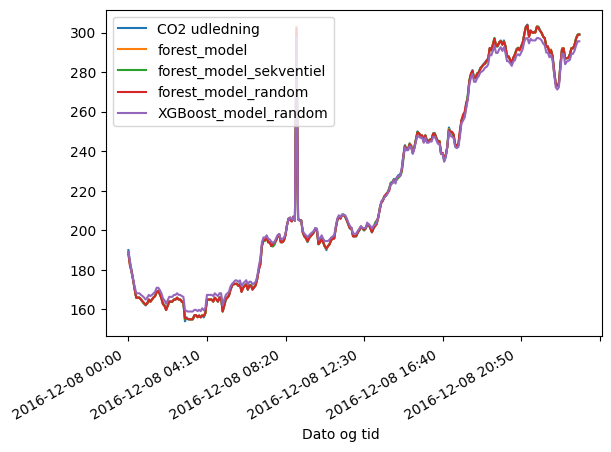

In [104]:
fig = co2.plot()
for k in result.keys():
    plot(result[k],label=k)
legend()
fig.figure.autofmt_xdate()


In [98]:
model = RandomForestRegressor()
model_xg = GradientBoostingRegressor()
param_grid={'n_estimators':[20,100,300],'max_features':[5,15,30]}

def grid_search(model,data):
    s = GridSearchCV(model,param_grid=param_grid)
    s.fit(*data)
    return s.score(*all_data)

grid_search(model,all_data)


0.999956013824669

In [100]:
print([grid_search(m,all_data) for m in [model,model_xg]])

[0.9998892239875847, 0.9999998920908079]


In [105]:
search = GridSearchCV(model,param_grid={'n_estimators':[20,100,300],'max_features':[5,15,30]})
search_xg = GridSearchCV(model_xg,param_grid={'n_estimators':[20,100,300],'max_features':[5,15,30]})

search.fit(*random_data)
search_xg.fit(*random_data)


,estimator,GradientBoostingRegressor()
,param_grid,"{'max_features': [5, 15, ...], 'n_estimators': [20, 100, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'squared_error'
